In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\Shelv\Downloads\FUTURE INTERSHIP\Resume\Resume.csv")

In [2]:
df.head()

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [3]:
df.shape

(2484, 4)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ID           2484 non-null   int64
 1   Resume_str   2484 non-null   str  
 2   Resume_html  2484 non-null   str  
 3   Category     2484 non-null   str  
dtypes: int64(1), str(3)
memory usage: 52.3 MB


In [5]:
df.isnull().sum()

ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64

In [6]:
df['Category'].nunique()

24

In [7]:
df['Category'].value_counts()

Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
FINANCE                   118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
AVIATION                  117
SALES                     116
HEALTHCARE                115
CONSULTANT                115
BANKING                   115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64

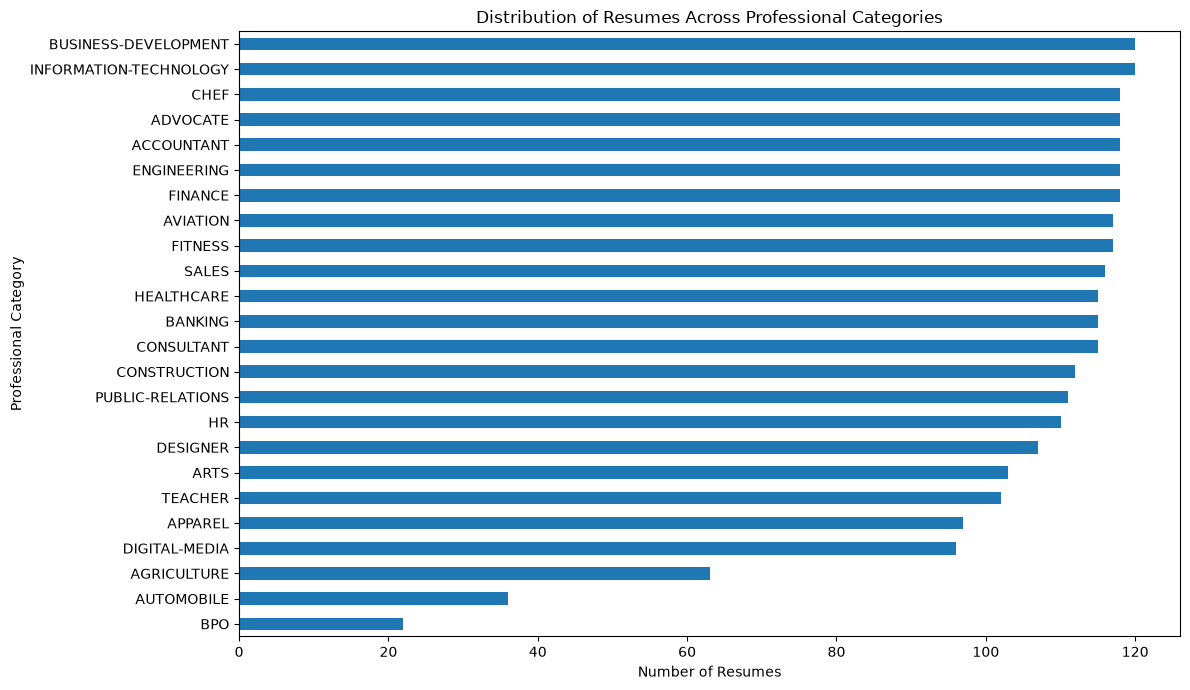

In [8]:
import matplotlib.pyplot as plt

category_counts = df['Category'].value_counts()

plt.figure(figsize=(12, 7))

category_counts.sort_values().plot(
    kind='barh'
)

plt.title('Distribution of Resumes Across Professional Categories')
plt.xlabel('Number of Resumes')
plt.ylabel('Professional Category')

plt.tight_layout()
plt.show()

In [9]:
df.duplicated(subset=['Resume_str']).sum()

np.int64(2)

In [10]:
(df['Resume_str'].str.strip() == '').sum()

np.int64(1)

In [11]:
df['Resume_str'].str.len().describe()

count     2484.000000
mean      6295.308776
std       2769.251458
min         21.000000
25%       5160.000000
50%       5886.500000
75%       7227.250000
max      38842.000000
Name: Resume_str, dtype: float64

In [12]:
duplicates = df[df.duplicated(subset=['Resume_str'], keep=False)]

duplicates[['ID', 'Category', 'Resume_str']]

,ID,Category,Resume_str
1490,19147603,FINANCE,FINANCE OFFICER Professional ...
1509,28398216,FINANCE,FINANCE OFFICER Professional ...
2444,16850314,AVIATION,STOREKEEPER II Professional Sum...
2483,37473139,AVIATION,STOREKEEPER II Professional Sum...


In [13]:
df[df['Resume_str'].str.strip() == ''][['ID', 'Category']]

,ID,Category
656,12632728,BUSINESS-DEVELOPMENT


In [14]:
df.assign(
    text_length=df['Resume_str'].str.len()
).nlargest(5, 'text_length')[['ID', 'Category', 'text_length']]

,ID,Category,text_length
1366,14663897,CHEF,38842
2111,11842274,PUBLIC-RELATIONS,35933
2007,39908485,CONSTRUCTION,30055
94,20806155,HR,24834
1817,10554236,ACCOUNTANT,24695


In [15]:
df.assign(
    text_length=df['Resume_str'].str.len()
).nsmallest(5, 'text_length')[['ID', 'Category', 'text_length']]

,ID,Category,text_length
656,12632728,BUSINESS-DEVELOPMENT,21
1931,22965804,CONSTRUCTION,881
130,21705160,DESIGNER,985
1102,14381464,SALES,995
1049,12696104,SALES,1033


In [16]:
df.loc[df['ID'] == 22965804, 'Resume_str'].iloc[0]

'         CONSTRUCTION WORKER           Highlights          Highly Motivated.  Dependable.  Ethical and honest.      Dedicated.  Hard working.              Experience      Company Name     May 2014   to   May 2014     Construction Worker   City  ,   State      I performed demolition work by taking down the rooms, cleaning them up and getting them ready to be remodeled.          Company Name     May 2013   to   August 2013     Assembly Line Painter   City  ,   State      Paint Shop Assembly line: E-Z Go.  I retrieve the parts from the paint shop and take them off the assembly line.          Company Name     April 2012   to   August 2012     Bus Washer   City  ,   State      Start date.  End date.          Education      Stetson University     2016       Bachelor of Science  :   International Business    City  ,   State  ,   US            Skills    Assembly, Paint Shop   '

In [17]:
df.loc[df['ID'] == 12632728, 'Resume_str'].iloc[0]

'                     '

In [18]:
duplicates = df[df.duplicated(subset='Resume_str', keep=False)]
duplicates[['ID', 'Category']]

,ID,Category
1490,19147603,FINANCE
1509,28398216,FINANCE
2444,16850314,AVIATION
2483,37473139,AVIATION


In [19]:
df_clean = df.drop_duplicates(subset='Resume_str', keep='first').copy()

df_clean.shape

(2482, 4)

In [20]:
df_clean.isnull().sum()

ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64

In [21]:
(df_clean['Resume_str'].str.strip() == '').sum()

np.int64(1)

In [22]:
df_clean = df_clean[df_clean['Resume_str'].str.strip() != ''].copy()

df_clean.shape

(2481, 4)

In [23]:
print("Duplicate resumes:", df_clean.duplicated(subset='Resume_str').sum())

print("Empty resumes:", (df_clean['Resume_str'].str.strip() == '').sum())

Duplicate resumes: 0
Empty resumes: 0


In [24]:
print(df_clean['Resume_str'].iloc[0])

         HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as    Hilton OnQ  ,   Micros    Opera PMS   , Fidelio    OPERA    Reservation System (ORS) ,   Holidex    Completed courses and seminars in customer service, sales strategies, inventory control, loss preve

In [25]:
df_clean['Category'].value_counts()

Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      119
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
FINANCE                   117
SALES                     116
AVIATION                  116
HEALTHCARE                115
CONSULTANT                115
BANKING                   115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64

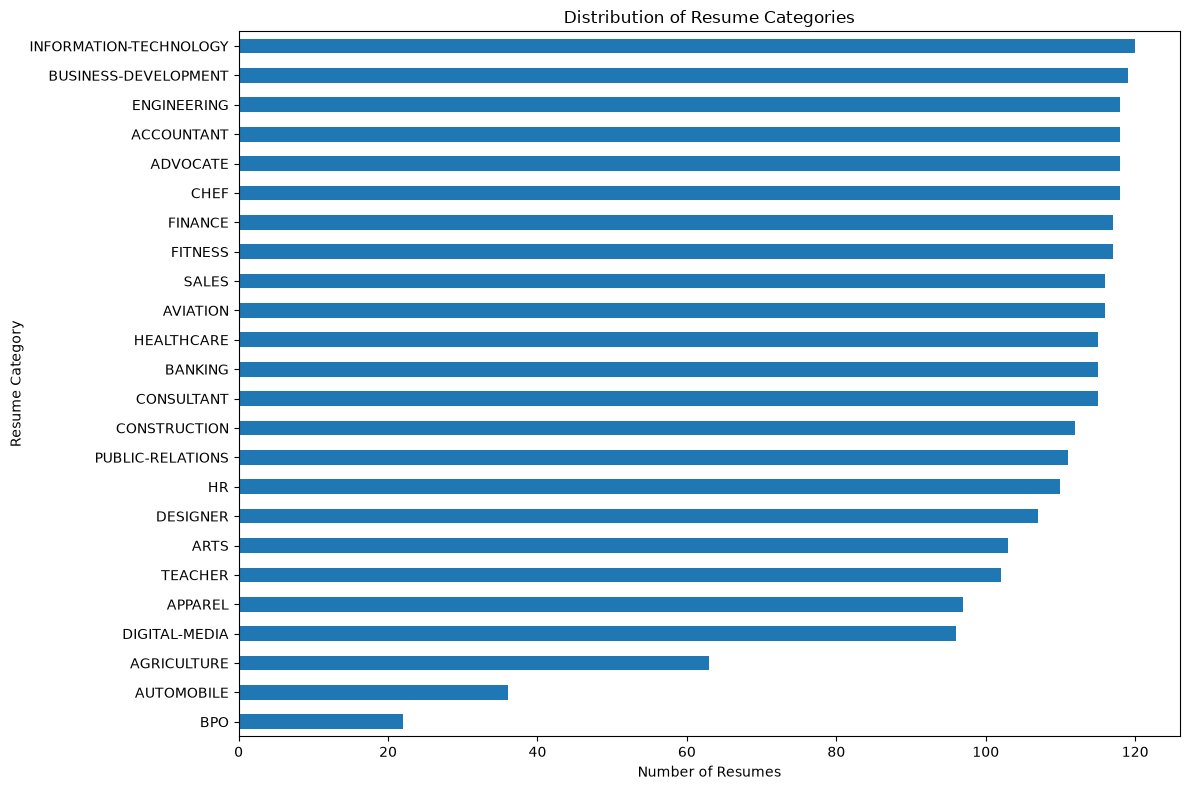

In [26]:
import matplotlib.pyplot as plt

category_counts = df_clean['Category'].value_counts()

plt.figure(figsize=(12, 8))
category_counts.sort_values().plot(kind='barh')

plt.title('Distribution of Resume Categories')
plt.xlabel('Number of Resumes')
plt.ylabel('Resume Category')
plt.tight_layout()
plt.show()

In [27]:
print("Largest category:", category_counts.max())
print("Smallest category:", category_counts.min())
print("Imbalance ratio:", round(category_counts.max() / category_counts.min(), 2))

Largest category: 120
Smallest category: 22
Imbalance ratio: 5.45


In [28]:
df_clean['Resume_clean'] = df_clean['Resume_str'].str.lower()

print(df_clean['Resume_clean'].iloc[0][:500])

         hr administrator/marketing associate

hr administrator       summary     dedicated customer service manager with 15+ years of experience in hospitality and customer service management.   respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         highlights         focused on customer satisfaction  team management  marketing savvy  conflict resolution techniques     training and development  skilled multi-task


In [29]:
import re

df_clean['Resume_clean'] = df_clean['Resume_clean'].apply(
    lambda x: re.sub(r'[^\w\s]', '', x)
)

print(df_clean['Resume_clean'].iloc[0][:500])

         hr administratormarketing associate

hr administrator       summary     dedicated customer service manager with 15 years of experience in hospitality and customer service management   respected builder and leader of customerfocused teams strives to instill a shared enthusiastic commitment to customer service         highlights         focused on customer satisfaction  team management  marketing savvy  conflict resolution techniques     training and development  skilled multitasker  clie


In [30]:
df_clean['Resume_clean'] = df_clean['Resume_str'].str.lower().apply(
    lambda x: re.sub(r'[^\w\s]', ' ', x)
)

print(df_clean['Resume_clean'].iloc[0][:500])

         hr administrator marketing associate

hr administrator       summary     dedicated customer service manager with 15  years of experience in hospitality and customer service management    respected builder and leader of customer focused teams  strives to instill a shared  enthusiastic commitment to customer service          highlights         focused on customer satisfaction  team management  marketing savvy  conflict resolution techniques     training and development  skilled multi task


In [31]:
df_clean['Resume_clean'] = df_clean['Resume_clean'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

print(df_clean['Resume_clean'].iloc[0][:500])

hr administrator marketing associate hr administrator summary dedicated customer service manager with 15 years of experience in hospitality and customer service management respected builder and leader of customer focused teams strives to instill a shared enthusiastic commitment to customer service highlights focused on customer satisfaction team management marketing savvy conflict resolution techniques training and development skilled multi tasker client relations specialist accomplishments miss


In [32]:
df_clean['Resume_clean'] = df_clean['Resume_clean'].apply(
    lambda x: re.sub(r'\d+', '', x)
)

print(df_clean['Resume_clean'].iloc[0][:500])

hr administrator marketing associate hr administrator summary dedicated customer service manager with  years of experience in hospitality and customer service management respected builder and leader of customer focused teams strives to instill a shared enthusiastic commitment to customer service highlights focused on customer satisfaction team management marketing savvy conflict resolution techniques training and development skilled multi tasker client relations specialist accomplishments missou


In [33]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [34]:
import nltk

print(nltk.__version__)

3.10.4


In [35]:
import nltk

nltk.download('stopwords', download_dir=r'C:\Users\Shelv\nltk_data')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Shelv\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [36]:
nltk.data.path.append(r'C:\Users\Shelv\nltk_data')

In [37]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

print("Stopwords loaded:", len(stop_words))

Stopwords loaded: 198


In [38]:
df_clean['Resume_clean'] = df_clean['Resume_clean'].apply(
    lambda x: ' '.join(
        word for word in x.split() if word not in stop_words
    )
)

print(df_clean['Resume_clean'].iloc[0][:500])


hr administrator marketing associate hr administrator summary dedicated customer service manager years experience hospitality customer service management respected builder leader customer focused teams strives instill shared enthusiastic commitment customer service highlights focused customer satisfaction team management marketing savvy conflict resolution techniques training development skilled multi tasker client relations specialist accomplishments missouri dot supervisor training certificati


In [39]:
(df_clean['Resume_clean'].str.strip() == '').sum()

np.int64(0)

In [40]:
df_clean['Word_Count'] = df_clean['Resume_clean'].apply(
    lambda x: len(x.split())
)

df_clean['Word_Count'].describe()

count    2481.000000
mean      593.559452
std       266.234979
min        78.000000
25%       482.000000
50%       554.000000
75%       682.000000
max      3581.000000
Name: Word_Count, dtype: float64

In [41]:
df_clean[['ID', 'Category', 'Word_Count']].nlargest(5, 'Word_Count')

,ID,Category,Word_Count
2111,11842274,PUBLIC-RELATIONS,3581
1366,14663897,CHEF,3504
2007,39908485,CONSTRUCTION,2860
1258,23085604,DIGITAL-MEDIA,2455
94,20806155,HR,2432


In [42]:
longest_resume = df_clean.loc[df_clean['Word_Count'].idxmax()]

print("Resume ID:", longest_resume['ID'])
print("Category:", longest_resume['Category'])
print("\nResume text:\n")
print(longest_resume['Resume_clean'][:1500])

Resume ID: 11842274
Category: PUBLIC-RELATIONS

Resume text:

bartender experience bartender company name city state marketing public relations years maintain proper adequate set bar daily basis responsible maintaining stock preparing storing garnishes juices perishables ensure product quality attend stand ups prior function obtain details order execute event flawlessly set breakdown mobile bars per hotel standards greets guests warm genuine hospitality promote sells product handle production consumption sheets assists cash bar set closing process perform general cleaning tasks adhere health department regulations bartender byron nelson golf tournament may dallas texas greet guests stock bar complete pre opening requirements maintain clean bar area prepare serve alcoholic beverages according standard recipes comply basic safety sanitation requirements organizational product operate club pos work large small events minimal supervision team environment complete pre closing requirements a

In [43]:
df_clean.nsmallest(5, 'Word_Count')[
    ['ID', 'Category', 'Word_Count']
]

,ID,Category,Word_Count
1931,22965804,CONSTRUCTION,78
130,21705160,DESIGNER,82
1049,12696104,SALES,87
1102,14381464,SALES,90
1039,98108571,SALES,104


In [44]:
shortest_resume = df_clean.loc[df_clean['Word_Count'].idxmin()]

print("Resume ID:", shortest_resume['ID'])
print("Category:", shortest_resume['Category'])
print("\nResume text:\n")
print(shortest_resume['Resume_clean'])

Resume ID: 22965804
Category: CONSTRUCTION

Resume text:

construction worker highlights highly motivated dependable ethical honest dedicated hard working experience company name may may construction worker city state performed demolition work taking rooms cleaning getting ready remodeled company name may august assembly line painter city state paint shop assembly line e z go retrieve parts paint shop take assembly line company name april august bus washer city state start date end date education stetson university bachelor science international business city state us skills assembly paint shop


In [45]:
(df_clean['Word_Count'] < 100).sum()

np.int64(4)

In [46]:
df_clean.columns.tolist()

['ID', 'Resume_str', 'Resume_html', 'Category', 'Resume_clean', 'Word_Count']

In [47]:
X = df_clean['Resume_clean']
y = df_clean['Category']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2481,)
y shape: (2481,)


In [48]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training resumes:", len(X_train))
print("Testing resumes:", len(X_test))

Training resumes: 1984
Testing resumes: 497


In [49]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000
)

In [50]:
# ==========================================
# RESUME SCREENING SYSTEM - PROJECT IMPORTS
# ==========================================

# 1. Data manipulation
import pandas as pd
import numpy as np

# 2. Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Text processing
import re
from sklearn.feature_extraction.text import TfidfVectorizer

# 4. Data splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

# 5. Machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

# 6. Machine learning pipelines
from sklearn.pipeline import Pipeline

# 7. Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 8. Model saving and loading
import joblib

print("All project libraries imported successfully!")

All project libraries imported successfully!


In [51]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

print("TF-IDF vectorizer configured successfully!")

TF-IDF vectorizer configured successfully!


In [52]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (1984, 5000)
Testing data shape: (497, 5000)


In [53]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

logistic_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [54]:
y_pred = logistic_model.predict(X_test_tfidf)

print("Predictions completed successfully!")
print("Number of predictions:", len(y_pred))

Predictions completed successfully!
Number of predictions: 497


In [55]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}")
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 0.6660
Model Accuracy: 66.60%


In [56]:
print(classification_report(y_test, y_pred))

                        precision    recall  f1-score   support

            ACCOUNTANT       0.56      0.83      0.67        24
              ADVOCATE       0.48      0.46      0.47        24
           AGRICULTURE       0.78      0.54      0.64        13
               APPAREL       0.57      0.21      0.31        19
                  ARTS       0.58      0.33      0.42        21
            AUTOMOBILE       0.83      0.71      0.77         7
              AVIATION       0.86      0.78      0.82        23
               BANKING       0.84      0.70      0.76        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.56      0.83      0.67        24
                  CHEF       0.85      0.71      0.77        24
          CONSTRUCTION       0.82      0.82      0.82        22
            CONSULTANT       0.71      0.22      0.33        23
              DESIGNER       0.82      0.86      0.84        21
         DIGITAL-MEDIA       0.69      

C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [57]:
svm_model = LinearSVC(
    class_weight='balanced',
    random_state=42,
    max_iter=2000
)

svm_model.fit(X_train_tfidf, y_train)

print("Linear SVM model trained successfully!")

Linear SVM model trained successfully!


In [58]:
svm_pred = svm_model.predict(X_test_tfidf)

print("SVM predictions completed successfully!")
print("Number of predictions:", len(svm_pred))

SVM predictions completed successfully!
Number of predictions: 497


In [59]:
svm_accuracy = accuracy_score(y_test, svm_pred)

print(f"SVM Accuracy: {svm_accuracy:.4f}")
print(f"SVM Accuracy: {svm_accuracy * 100:.2f}%")

SVM Accuracy: 0.7183
SVM Accuracy: 71.83%


In [60]:
print(classification_report(y_test, svm_pred))

                        precision    recall  f1-score   support

            ACCOUNTANT       0.60      0.88      0.71        24
              ADVOCATE       0.69      0.75      0.72        24
           AGRICULTURE       0.80      0.62      0.70        13
               APPAREL       0.56      0.26      0.36        19
                  ARTS       0.69      0.43      0.53        21
            AUTOMOBILE       0.57      0.57      0.57         7
              AVIATION       0.87      0.87      0.87        23
               BANKING       0.86      0.78      0.82        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.71      0.83      0.77        24
                  CHEF       0.89      0.71      0.79        24
          CONSTRUCTION       0.74      0.77      0.76        22
            CONSULTANT       0.73      0.35      0.47        23
              DESIGNER       0.83      0.90      0.86        21
         DIGITAL-MEDIA       0.80      

In [61]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [62]:
nb_pred = nb_model.predict(X_test_tfidf)

print("Naive Bayes predictions completed successfully!")
print("Number of predictions:", len(nb_pred))

Naive Bayes predictions completed successfully!
Number of predictions: 497


In [63]:
nb_accuracy = accuracy_score(y_test, nb_pred)

print(f"Naive Bayes Accuracy: {nb_accuracy:.4f}")
print(f"Naive Bayes Accuracy: {nb_accuracy * 100:.2f}%")

Naive Bayes Accuracy: 0.5553
Naive Bayes Accuracy: 55.53%


In [64]:
print(classification_report(y_test, nb_pred))

                        precision    recall  f1-score   support

            ACCOUNTANT       0.46      0.88      0.60        24
              ADVOCATE       0.32      0.42      0.36        24
           AGRICULTURE       1.00      0.08      0.14        13
               APPAREL       0.00      0.00      0.00        19
                  ARTS       0.50      0.05      0.09        21
            AUTOMOBILE       0.00      0.00      0.00         7
              AVIATION       0.83      0.65      0.73        23
               BANKING       0.87      0.57      0.68        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.41      0.88      0.56        24
                  CHEF       0.78      0.75      0.77        24
          CONSTRUCTION       0.67      0.73      0.70        22
            CONSULTANT       1.00      0.04      0.08        23
              DESIGNER       0.76      0.62      0.68        21
         DIGITAL-MEDIA       0.62      

C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [65]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [66]:
rf_pred = rf_model.predict(X_test_tfidf)

print("Random Forest predictions completed successfully!")
print("Number of predictions:", len(rf_pred))

Random Forest predictions completed successfully!
Number of predictions: 497


In [67]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")

Random Forest Accuracy: 0.7686
Random Forest Accuracy: 76.86%


In [68]:
print(classification_report(y_test, rf_pred))

                        precision    recall  f1-score   support

            ACCOUNTANT       0.64      0.96      0.77        24
              ADVOCATE       0.90      0.75      0.82        24
           AGRICULTURE       1.00      0.69      0.82        13
               APPAREL       0.89      0.42      0.57        19
                  ARTS       0.50      0.14      0.22        21
            AUTOMOBILE       1.00      0.43      0.60         7
              AVIATION       0.83      0.83      0.83        23
               BANKING       0.74      0.61      0.67        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.96      0.96      0.96        24
                  CHEF       0.86      0.79      0.83        24
          CONSTRUCTION       0.95      0.95      0.95        22
            CONSULTANT       0.79      0.65      0.71        23
              DESIGNER       0.83      0.95      0.89        21
         DIGITAL-MEDIA       0.81      

C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


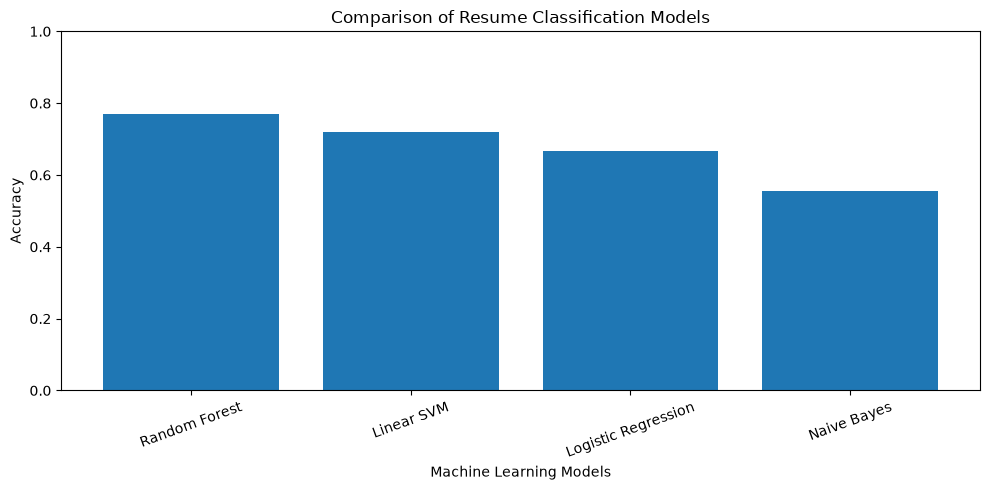

In [69]:
model_names = [
    'Random Forest',
    'Linear SVM',
    'Logistic Regression',
    'Naive Bayes'
]

model_accuracies = [
    rf_accuracy,
    svm_accuracy,
    accuracy,
    nb_accuracy
]

plt.figure(figsize=(10, 5))

plt.bar(model_names, model_accuracies)

plt.title('Comparison of Resume Classification Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [70]:
rf_parameters = {
    'n_estimators': [200, 300, 500],
    'max_depth': [None, 30, 50],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),
    param_grid=rf_parameters,
    cv=3,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train_tfidf, y_train)

Fitting 3 folds for each of 36 candidates, totalling 108 fits


C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
6 fits failed out of a total of 108.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3 fits failed with the following error:
joblib.externals.loky.process_executor._RemoteTraceback: 
"""
Traceback (most recent call last):
  File "C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\joblib\_utils.py", line 109, in __call__
    return self.func(**kwargs)
           ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\joblib\parallel.py", line 607, in __call__
    return [func(*args, **kwargs) for func, args, kwargs in self.items]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 30, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [200, 300, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_weighted'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_

In [112]:
print("Best Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(rf_grid.best_score_)

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 500}

Best Cross-Validation F1-Score:
0.7286848675979031


In [72]:
best_rf_model = rf_grid.best_estimator_

tuned_rf_pred = best_rf_model.predict(X_test_tfidf)

tuned_rf_accuracy = accuracy_score(y_test, tuned_rf_pred)

print("Tuned Random Forest Accuracy:", tuned_rf_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, tuned_rf_pred))

Tuned Random Forest Accuracy: 0.772635814889336

Classification Report:
                        precision    recall  f1-score   support

            ACCOUNTANT       0.59      0.96      0.73        24
              ADVOCATE       0.94      0.71      0.81        24
           AGRICULTURE       1.00      0.69      0.82        13
               APPAREL       0.89      0.42      0.57        19
                  ARTS       0.50      0.14      0.22        21
            AUTOMOBILE       1.00      0.57      0.73         7
              AVIATION       0.83      0.83      0.83        23
               BANKING       0.76      0.70      0.73        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.92      0.92      0.92        24
                  CHEF       0.86      0.79      0.83        24
          CONSTRUCTION       0.95      0.91      0.93        22
            CONSULTANT       0.82      0.61      0.70        23
              DESIGNER       0.

C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Shelv\.conda\envs\dl_env\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [73]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Linear SVM',
        'Naive Bayes',
        'Original Random Forest',
        'Tuned Random Forest'
    ],
    'Accuracy': [
        accuracy,
        svm_accuracy,
        nb_accuracy,
        rf_accuracy,
        tuned_rf_accuracy
    ],
    'Weighted F1-Score': [
        f1_score(y_test, y_pred, average='weighted'),
        f1_score(y_test, svm_pred, average='weighted'),
        f1_score(y_test, nb_pred, average='weighted'),
        f1_score(y_test, rf_pred, average='weighted'),
        f1_score(y_test, tuned_rf_pred, average='weighted')
    ]
})

model_comparison = model_comparison.sort_values(
    by='Weighted F1-Score',
    ascending=False
)

print(model_comparison.round(4))

                    Model  Accuracy  Weighted F1-Score
4     Tuned Random Forest    0.7726             0.7580
3  Original Random Forest    0.7686             0.7540
1              Linear SVM    0.7183             0.7084
0     Logistic Regression    0.6660             0.6515
2             Naive Bayes    0.5553             0.5094


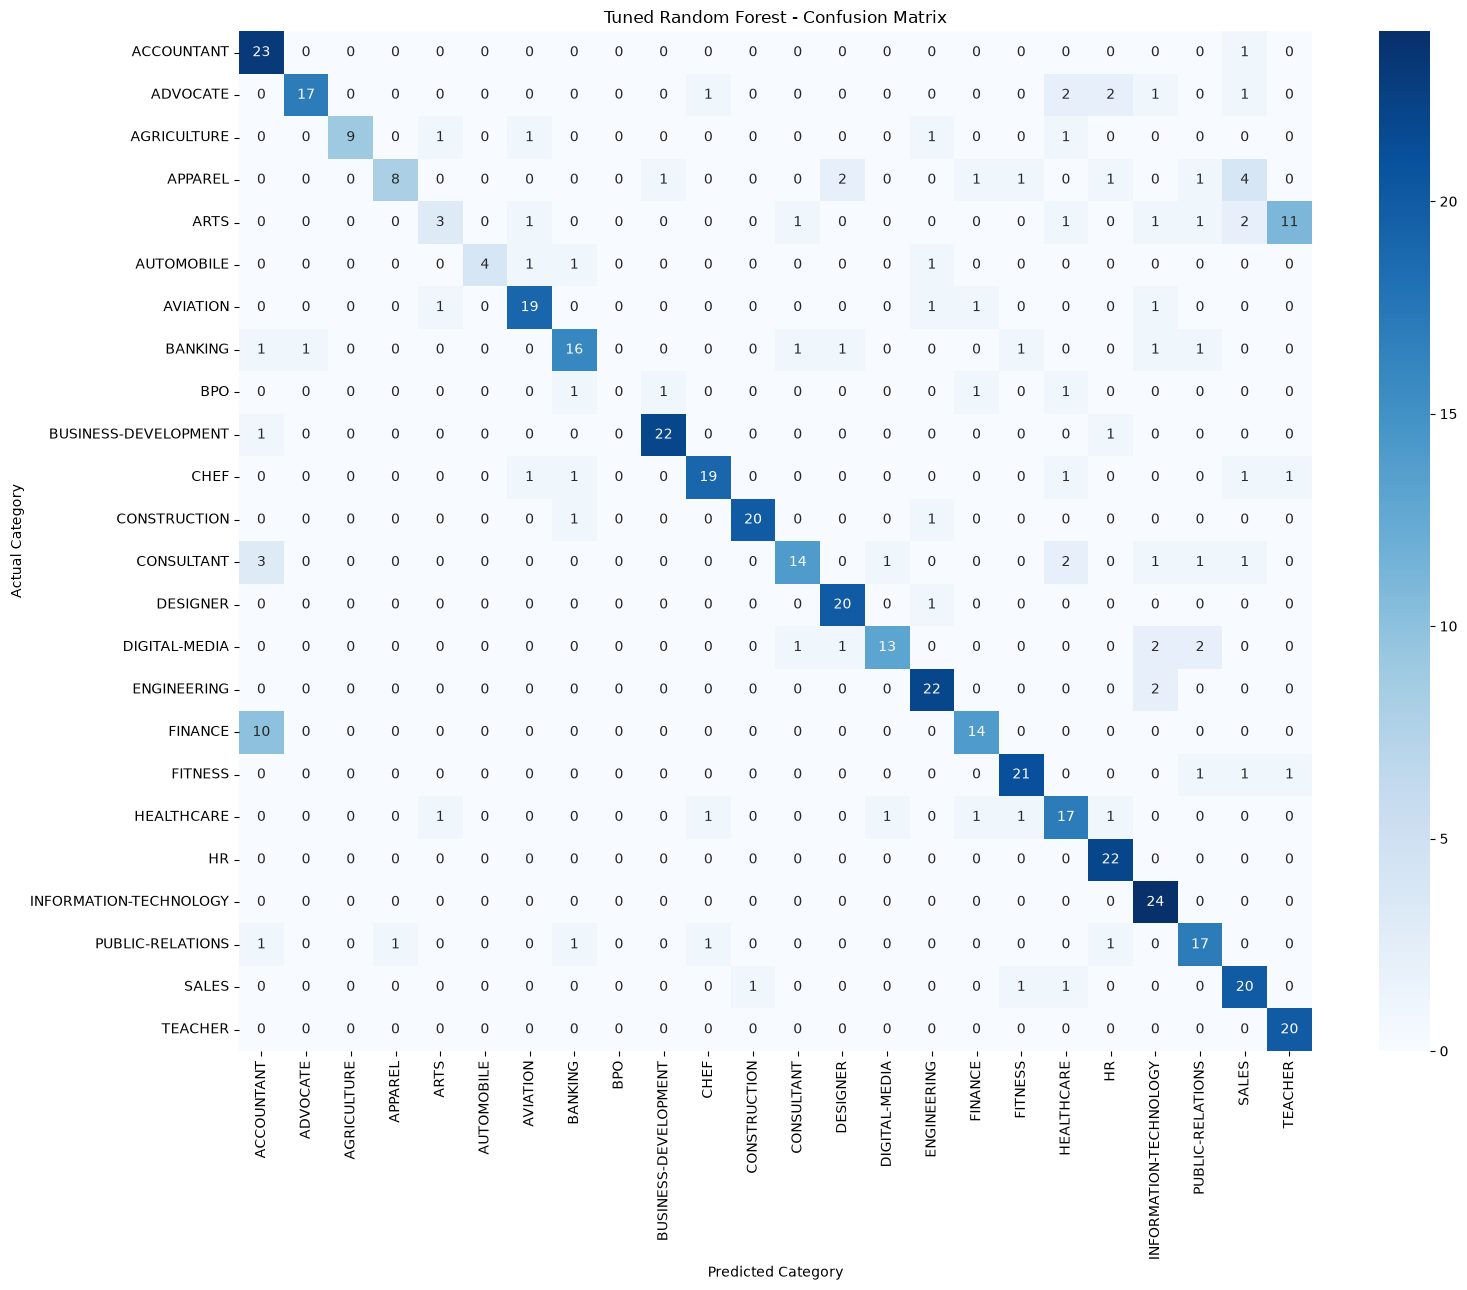

In [74]:
cm = confusion_matrix(
    y_test,
    tuned_rf_pred,
    labels=best_rf_model.classes_
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_rf_model.classes_,
    yticklabels=best_rf_model.classes_
)

plt.title('Tuned Random Forest - Confusion Matrix')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [75]:
import pandas as pd
import numpy as np

labels = best_rf_model.classes_

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

# Remove correct predictions along the diagonal
np.fill_diagonal(cm, 0)

# Find the most frequent classification errors
errors = []

for i, actual_category in enumerate(labels):
    for j, predicted_category in enumerate(labels):
        if cm[i, j] > 0:
            errors.append({
                'Actual Category': actual_category,
                'Predicted Category': predicted_category,
                'Number of Errors': cm[i, j]
            })

error_df = pd.DataFrame(errors)

error_df = error_df.sort_values(
    by='Number of Errors',
    ascending=False
)

print(error_df.head(15).to_string(index=False))

Actual Category     Predicted Category  Number of Errors
           ARTS                TEACHER                11
        FINANCE             ACCOUNTANT                10
        APPAREL                  SALES                 4
     CONSULTANT             ACCOUNTANT                 3
        APPAREL               DESIGNER                 2
           ARTS                  SALES                 2
       ADVOCATE             HEALTHCARE                 2
       ADVOCATE                     HR                 2
     CONSULTANT             HEALTHCARE                 2
    ENGINEERING INFORMATION-TECHNOLOGY                 2
  DIGITAL-MEDIA       PUBLIC-RELATIONS                 2
  DIGITAL-MEDIA INFORMATION-TECHNOLOGY                 2
     ACCOUNTANT                  SALES                 1
       ADVOCATE                  SALES                 1
    AGRICULTURE                   ARTS                 1


In [76]:
arts_mistakes = df_clean.loc[
    X_test.index[
        (y_test == 'ARTS') &
        (tuned_rf_pred == 'TEACHER')
    ]
]

for _, row in arts_mistakes.iterrows():
    print("Resume ID:", row['ID'])
    print("Actual Category:", row['Category'])
    print("Predicted Category: TEACHER")
    print("\nResume excerpt:")
    print(row['Resume_str'][:1200])
    print("\n" + "=" * 80 + "\n")

Resume ID: 23752500
Actual Category: ARTS
Predicted Category: TEACHER

Resume excerpt:
         LANGUAGE ARTS TEACHER           Professional Summary    To continue working with children, as well as youth where I will be able to utilize all skills in my expertise area (elementary/middle school.)      Core Qualifications         Ability to communicate, inspire trust and confidence, and motivate children, as well as understand children's educational and emotional needs.   Ability to recognize and respond to individual and cultural differences in children and employ different teaching methods that will result in higher student achievement.   Organized, dependable, patient, and creative.   Able to work cooperatively and communicate effectively with other teachers, support staff, parents, and members of the community.     Computer skills (WordPerfect, Microsoft Word, and PowerPoint) and Leadership skills            Experience       Language Arts Teacher    August 2007   to   Current     Comp

In [77]:
finance_mistakes = df_clean.loc[
    X_test.index[
        (y_test == 'FINANCE') &
        (tuned_rf_pred == 'ACCOUNTANT')
    ]
]

for _, row in finance_mistakes.iterrows():
    print("Resume ID:", row['ID'])
    print("Actual Category:", row['Category'])
    print("Predicted Category: ACCOUNTANT")
    print("\nResume excerpt:")
    print(row['Resume_str'][:1200])
    print("\n" + "=" * 80 + "\n")

Resume ID: 24670867
Actual Category: FINANCE
Predicted Category: ACCOUNTANT

Resume excerpt:
         GLOBAL FINANCE ACCOUNTANT       Summary    Honest, reliable, dependable, hardworking, quick learner, enthusiastic, motivated individual with strong work ethics, who is results driven, detail oriented, and well organized with a fervent desire to learn and be part of a professional team which offers continued opportunities for professional and personal growth.      Skills        Excellent people and self-management techniques, Excellent Client or Business partner relations, Excellent Written and Oral communication abilities, Excellent problem-solving skills, File maintenance, Experience using Windows 98, 2000, 2007, 2010, 2013, Power Point, MS Outlook, MS Word, Bolt, MAC, Millennium, Internet, SAP 7.5, Sabre, Great Plains, Lawson HRIS, CSG, ProAlpha, Quick Books, Centricity, AS400, Oracle R11, Oracle R12, MAS 90, Kofax, Excel. Knowledge of Financial Management and human resource, SOX com

In [78]:
feature_names = tfidf.get_feature_names_out()

importances = best_rf_model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(20).to_string(index=False))

               Feature  Importance
          construction    0.009541
              designer    0.009482
              advocate    0.008553
               fitness    0.008128
              aviation    0.007648
           engineering    0.007559
            healthcare    0.007241
  business development    0.007146
                  chef    0.006189
information technology    0.006183
               teacher    0.006083
            consultant    0.005966
               finance    0.005884
                    hr    0.005705
              aircraft    0.005698
               digital    0.005380
                 media    0.005311
      experience sales    0.005125
                 sales    0.005065
               banking    0.004856


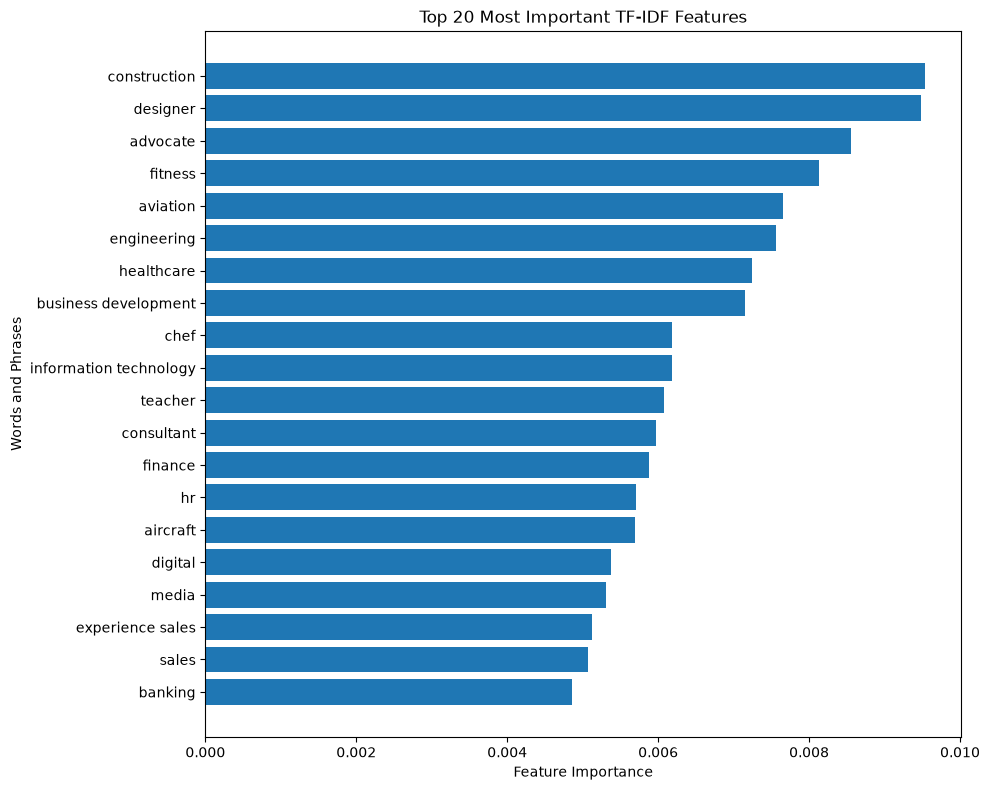

In [79]:
top_features = feature_importance.head(20).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Words and Phrases')
plt.title('Top 20 Most Important TF-IDF Features')

plt.tight_layout()
plt.show()

In [80]:
report = classification_report(
    y_test,
    tuned_rf_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

category_report = report_df.iloc[:-3][
    ['precision', 'recall', 'f1-score']
]

category_report.head()

,precision,recall,f1-score
ACCOUNTANT,0.589744,0.958333,0.730159
ADVOCATE,0.944444,0.708333,0.809524
AGRICULTURE,1.000000,0.692308,0.818182
APPAREL,0.888889,0.421053,0.571429
ARTS,0.500000,0.142857,0.222222


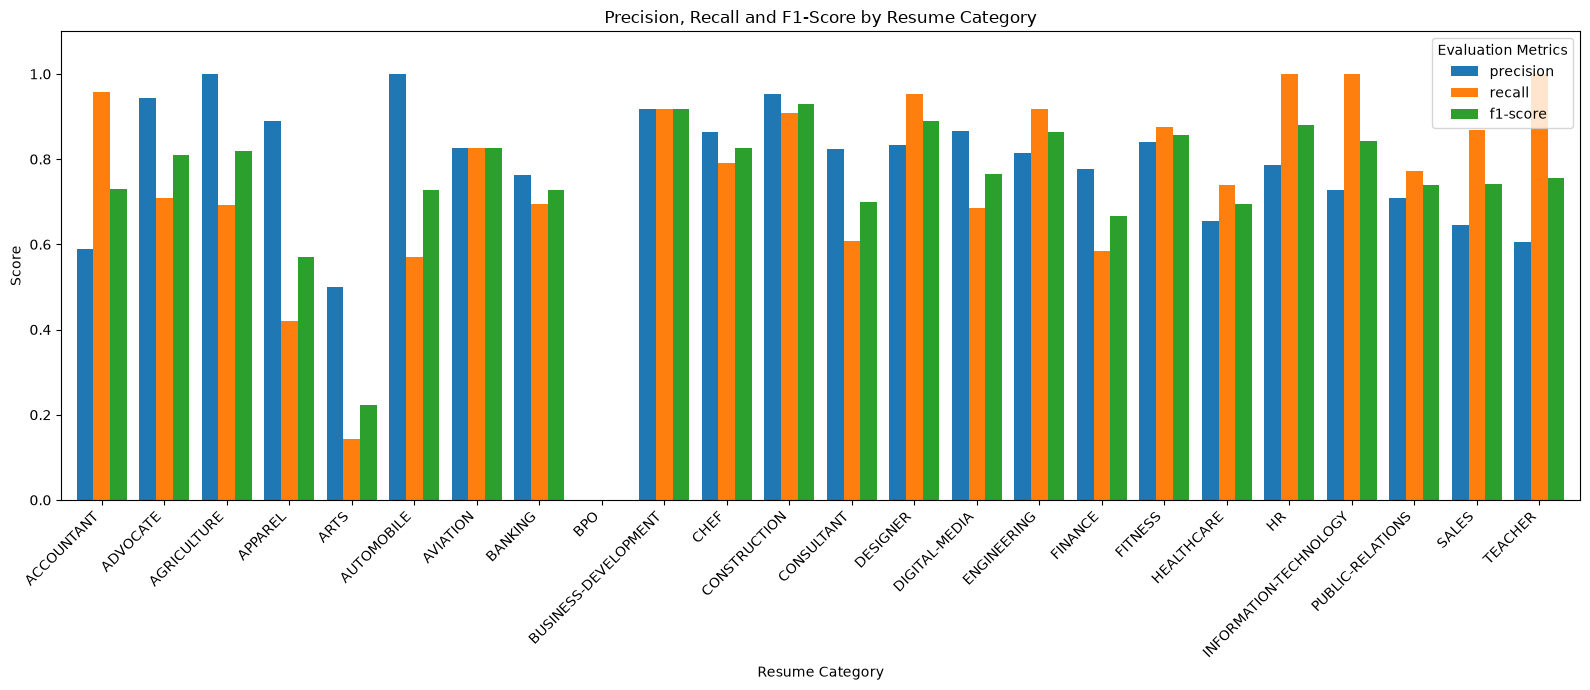

In [81]:
category_report.plot(
    kind='bar',
    figsize=(16, 7),
    width=0.8
)

plt.title('Precision, Recall and F1-Score by Resume Category')
plt.xlabel('Resume Category')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()

In [82]:
weakest_categories = category_report.sort_values(
    by='f1-score',
    ascending=True
)

weakest_categories

,precision,recall,f1-score
BPO,0.000000,0.000000,0.000000
ARTS,0.500000,0.142857,0.222222
APPAREL,0.888889,0.421053,0.571429
FINANCE,0.777778,0.583333,0.666667
HEALTHCARE,0.653846,0.739130,0.693878
CONSULTANT,0.823529,0.608696,0.700000
AUTOMOBILE,1.000000,0.571429,0.727273
BANKING,0.761905,0.695652,0.727273
ACCOUNTANT,0.589744,0.958333,0.730159
PUBLIC-RELATIONS,0.708333,0.772727,0.739130


In [83]:
bpo_resumes = df_clean[
    df_clean['Category'] == 'BPO'
][['ID', 'Category', 'Word_Count', 'Resume_clean']]

print("Total BPO resumes:", len(bpo_resumes))

bpo_resumes[['ID', 'Category', 'Word_Count']]

Total BPO resumes: 22


,ID,Category,Word_Count
972,79261033,BPO,447
973,16492045,BPO,580
974,18589927,BPO,304
975,23933031,BPO,819
976,13964744,BPO,721
977,89512321,BPO,777
978,30709029,BPO,491
979,11183737,BPO,772
980,63158213,BPO,628
981,24727739,BPO,692


In [84]:
for index, row in bpo_resumes.head(5).iterrows():
    print("=" * 80)
    print("Resume ID:", row['ID'])
    print("Word Count:", row['Word_Count'])
    print(row['Resume_clean'][:1200])
    print("\n")

Resume ID: 79261033
Word Count: 447
director operations bpo executive summary results focused management professional offering years progressive leadership experience transforms high potential staff outstanding leaders demonstrate creativity savvy critical financial operational success high energy manager successful building motivating dynamic teams cultivates company culture staff members feel comfortable voicing questions concerns well contributing new ideas drive company growth core competencies operations management staff development change management cross functional team management complex problem solving calm pressure computer savvy skilled negotiator experience director operations bpo company name city state responsible sales locations employees managed team professional consisted hiring training performance management strengthened client relationship client concentrix increased client revenue million million monthly basis surpassed revenue goals four consecutive quarters basis

In [85]:
bpo_test_results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': tuned_rf_pred
})

bpo_test_results = bpo_test_results[
    bpo_test_results['Actual'] == 'BPO'
]

bpo_test_results

,Actual,Predicted
972,BPO,BUSINESS-DEVELOPMENT
993,BPO,HEALTHCARE
984,BPO,FINANCE
975,BPO,BANKING


In [86]:
print("BPO training examples:", (y_train == 'BPO').sum())
print("BPO testing examples:", (y_test == 'BPO').sum())

BPO training examples: 18
BPO testing examples: 4


In [87]:
training_distribution = y_train.value_counts().sort_values()

print(training_distribution.to_string())

Category
BPO                       18
AUTOMOBILE                29
AGRICULTURE               50
DIGITAL-MEDIA             77
APPAREL                   78
TEACHER                   82
ARTS                      82
DESIGNER                  86
HR                        88
PUBLIC-RELATIONS          89
CONSTRUCTION              90
BANKING                   92
CONSULTANT                92
HEALTHCARE                92
FINANCE                   93
FITNESS                   93
AVIATION                  93
SALES                     93
ENGINEERING               94
ACCOUNTANT                94
CHEF                      94
ADVOCATE                  94
BUSINESS-DEVELOPMENT      95
INFORMATION-TECHNOLOGY    96


In [88]:
class_weight='balanced'

In [89]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = pd.DataFrame({
    'Category': classes,
    'Class_Weight': weights
})

class_weights.sort_values(
    by='Class_Weight',
    ascending=False
)

,Category,Class_Weight
8,BPO,4.592593
5,AUTOMOBILE,2.850575
2,AGRICULTURE,1.653333
14,DIGITAL-MEDIA,1.073593
3,APPAREL,1.059829
23,TEACHER,1.008130
4,ARTS,1.008130
13,DESIGNER,0.961240
19,HR,0.939394
21,PUBLIC-RELATIONS,0.928839


In [90]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [91]:
import imblearn

print("Imbalanced-learn version:", imblearn.__version__)

Imbalanced-learn version: 0.14.2


In [92]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_resampled, y_train_resampled = ros.fit_resample(
    X_train_tfidf,
    y_train
)

print("Original training shape:", X_train_tfidf.shape)
print("Resampled training shape:", X_train_resampled.shape)

print("\nResampled category distribution:")
print(y_train_resampled.value_counts().sort_values())

Original training shape: (1984, 5000)
Resampled training shape: (2304, 5000)

Resampled category distribution:
Category
PUBLIC-RELATIONS          96
ACCOUNTANT                96
FINANCE                   96
FITNESS                   96
DESIGNER                  96
CONSTRUCTION              96
DIGITAL-MEDIA             96
SALES                     96
ENGINEERING               96
ADVOCATE                  96
AVIATION                  96
CHEF                      96
HR                        96
BUSINESS-DEVELOPMENT      96
INFORMATION-TECHNOLOGY    96
HEALTHCARE                96
AGRICULTURE               96
TEACHER                   96
ARTS                      96
BANKING                   96
CONSULTANT                96
APPAREL                   96
BPO                       96
AUTOMOBILE                96
Name: count, dtype: int64


In [93]:
oversampled_rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=1,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

oversampled_rf_model.fit(
    X_train_resampled,
    y_train_resampled
)

print("Oversampled Random Forest training completed!")

Oversampled Random Forest training completed!


In [94]:
oversampled_rf_pred = oversampled_rf_model.predict(X_test_tfidf)

oversampled_accuracy = accuracy_score(y_test, oversampled_rf_pred)
oversampled_f1 = f1_score(y_test, oversampled_rf_pred, average='weighted')
oversampled_macro_f1 = f1_score(y_test, oversampled_rf_pred, average='macro')

print("Accuracy:", round(oversampled_accuracy * 100, 2), "%")
print("Weighted F1-score:", round(oversampled_f1 * 100, 2), "%")
print("Macro F1-score:", round(oversampled_macro_f1 * 100, 2), "%")

Accuracy: 76.46 %
Weighted F1-score: 75.08 %
Macro F1-score: 71.55 %


In [95]:
print("ORIGINAL RANDOM FOREST")
print(classification_report(
    y_test,
    tuned_rf_pred,
    labels=['BPO'],
    zero_division=0
))

print("\nOVERSAMPLED RANDOM FOREST")
print(classification_report(
    y_test,
    oversampled_rf_pred,
    labels=['BPO'],
    zero_division=0
))

ORIGINAL RANDOM FOREST
              precision    recall  f1-score   support

         BPO       0.00      0.00      0.00         4

   micro avg       0.00      0.00      0.00         4
   macro avg       0.00      0.00      0.00         4
weighted avg       0.00      0.00      0.00         4


OVERSAMPLED RANDOM FOREST
              precision    recall  f1-score   support

         BPO       0.00      0.00      0.00         4

   micro avg       0.00      0.00      0.00         4
   macro avg       0.00      0.00      0.00         4
weighted avg       0.00      0.00      0.00         4



In [96]:
print(classification_report(
    y_test,
    svm_pred,
    labels=['BPO'],
    zero_division=0
))

              precision    recall  f1-score   support

         BPO       0.00      0.00      0.00         4

   micro avg       0.00      0.00      0.00         4
   macro avg       0.00      0.00      0.00         4
weighted avg       0.00      0.00      0.00         4



In [97]:
svm_bpo_results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': svm_pred
})

svm_bpo_results[
    svm_bpo_results['Actual'] == 'BPO'
]

,Actual,Predicted
972,BPO,BUSINESS-DEVELOPMENT
993,BPO,HEALTHCARE
984,BPO,FINANCE
975,BPO,BANKING


In [98]:
from collections import Counter

bpo_text = ' '.join(
    df_clean.loc[
        df_clean['Category'] == 'BPO',
        'Resume_clean'
    ]
)

bpo_word_counts = Counter(bpo_text.split())

bpo_common_words = pd.DataFrame(
    bpo_word_counts.most_common(30),
    columns=['Word', 'Frequency']
)

bpo_common_words

,Word,Frequency
0,management,208
1,company,130
2,team,127
3,city,116
4,name,115
5,business,107
6,state,105
7,client,103
8,process,99
9,customer,89


In [99]:
from sklearn.feature_extraction.text import CountVectorizer

bpo_vectorizer = CountVectorizer(
    stop_words='english',
    max_features=100
)

bpo_counts = bpo_vectorizer.fit_transform(
    df_clean['Resume_clean']
)

bpo_features = bpo_vectorizer.get_feature_names_out()

bpo_word_totals = np.asarray(
    bpo_counts[df_clean['Category'].values == 'BPO'].sum(axis=0)
).flatten()

other_word_totals = np.asarray(
    bpo_counts[df_clean['Category'].values != 'BPO'].sum(axis=0)
).flatten()

bpo_comparison = pd.DataFrame({
    'Word': bpo_features,
    'BPO_Frequency': bpo_word_totals,
    'Other_Categories_Frequency': other_word_totals
})

bpo_comparison.sort_values(
    by='BPO_Frequency',
    ascending=False
).head(20)

,Word,BPO_Frequency,Other_Categories_Frequency
44,management,208,11961
11,company,130,15074
89,team,127,5945
7,city,116,14948
6,business,107,7757
84,state,105,16046
8,client,103,3156
58,process,99,3328
15,customer,89,7835
79,service,85,6134


In [100]:
bpo_comparison['BPO_Rate'] = (
    bpo_comparison['BPO_Frequency'] / 
    (df_clean['Category'] == 'BPO').sum()
)

bpo_comparison['Other_Rate'] = (
    bpo_comparison['Other_Categories_Frequency'] /
    (df_clean['Category'] != 'BPO').sum()
)

bpo_comparison['BPO_Ratio'] = (
    bpo_comparison['BPO_Rate'] /
    bpo_comparison['Other_Rate']
)

bpo_comparison.sort_values(
    by='BPO_Ratio',
    ascending=False
).head(20)

,Word,BPO_Frequency,Other_Categories_Frequency,BPO_Rate,Other_Rate,BPO_Ratio
8,client,103,3156,4.681818,1.283449,3.647842
58,process,99,3328,4.500000,1.353396,3.324970
54,performance,64,2450,2.909091,0.996340,2.919777
96,various,50,1945,2.272727,0.790972,2.873335
53,operations,73,2935,3.318182,1.193575,2.780037
89,team,127,5945,5.772727,2.417649,2.387744
87,support,78,4043,3.545455,1.644164,2.156387
37,issues,40,2232,1.818182,0.907686,2.003095
44,management,208,11961,9.454545,4.864172,1.943711
40,leadership,40,2360,1.818182,0.959740,1.894453


In [101]:
bpo_terms = [
    'bpo',
    'call center',
    'call centre',
    'contact center',
    'contact centre',
    'inbound',
    'outbound',
    'customer service',
    'workforce management',
    'business process',
    'client support',
    'customer support',
    'technical support',
    'service level',
    'quality assurance',
    'operations management'
]

bpo_term_results = []

for term in bpo_terms:
    bpo_matches = df_clean[
        (df_clean['Category'] == 'BPO') &
        (df_clean['Resume_clean'].str.contains(term, regex=False))
    ].shape[0]

    other_matches = df_clean[
        (df_clean['Category'] != 'BPO') &
        (df_clean['Resume_clean'].str.contains(term, regex=False))
    ].shape[0]

    bpo_term_results.append({
        'Term': term,
        'BPO_Resumes': bpo_matches,
        'Other_Resumes': other_matches
    })

bpo_term_df = pd.DataFrame(bpo_term_results)

bpo_term_df.sort_values(
    by='BPO_Resumes',
    ascending=False
)

,Term,BPO_Resumes,Other_Resumes
7,customer service,11,982
0,bpo,10,16
1,call center,8,113
14,quality assurance,6,230
12,technical support,6,151
5,inbound,5,106
6,outbound,4,97
15,operations management,4,115
13,service level,3,81
9,business process,3,125


In [102]:
bpo_resumes = df_clean[
    df_clean['Category'] == 'BPO'
][['ID', 'Resume_clean', 'Word_Count']]

for _, row in bpo_resumes.iterrows():
    print(f"\nResume ID: {row['ID']}")
    print(f"Word Count: {row['Word_Count']}")
    print(row['Resume_clean'][:700])
    print("-" * 80)


Resume ID: 79261033
Word Count: 447
director operations bpo executive summary results focused management professional offering years progressive leadership experience transforms high potential staff outstanding leaders demonstrate creativity savvy critical financial operational success high energy manager successful building motivating dynamic teams cultivates company culture staff members feel comfortable voicing questions concerns well contributing new ideas drive company growth core competencies operations management staff development change management cross functional team management complex problem solving calm pressure computer savvy skilled negotiator experience director operations bpo company name city state responsibl
--------------------------------------------------------------------------------

Resume ID: 16492045
Word Count: 580
bpo team leader summary seeking provide top quality support ensure competitive advantage global marketplace accomplishments recognized playing i

In [103]:
bpo_predictions = pd.DataFrame({
    'ID': df_clean.loc[y_test.index, 'ID'],
    'Actual_Category': y_test,
    'Predicted_Category': tuned_rf_pred
})

bpo_predictions = bpo_predictions[
    bpo_predictions['Actual_Category'] == 'BPO'
]

bpo_predictions

,ID,Actual_Category,Predicted_Category
972,79261033,BPO,BUSINESS-DEVELOPMENT
993,45077654,BPO,HEALTHCARE
984,31064969,BPO,FINANCE
975,23933031,BPO,BANKING


In [104]:
bpo_train_predictions = pd.DataFrame({
    'ID': df_clean.loc[X_train.index, 'ID'],
    'Actual_Category': y_train,
    'Predicted_Category': best_rf_model.predict(X_train_tfidf)
})

bpo_train_predictions = bpo_train_predictions[
    bpo_train_predictions['Actual_Category'] == 'BPO'
]

bpo_train_predictions

,ID,Actual_Category,Predicted_Category
990,26829350,BPO,BPO
973,16492045,BPO,BPO
981,24727739,BPO,BPO
983,69097572,BPO,BPO
985,38707449,BPO,BPO
982,15145575,BPO,BPO
980,63158213,BPO,BPO
986,57706851,BPO,BPO
992,19362586,BPO,BPO
988,27710853,BPO,BPO


In [105]:
arts_predictions = pd.DataFrame({
    'ID': df_clean.loc[y_test.index, 'ID'],
    'Actual_Category': y_test,
    'Predicted_Category': tuned_rf_pred
})

arts_predictions = arts_predictions[
    arts_predictions['Actual_Category'] == 'ARTS'
]

arts_predictions

,ID,Actual_Category,Predicted_Category
2308,21867728,ARTS,CONSULTANT
2329,39608848,ARTS,PUBLIC-RELATIONS
2271,23752500,ARTS,TEACHER
2320,27936502,ARTS,TEACHER
2351,25926667,ARTS,TEACHER
2278,46055835,ARTS,TEACHER
2299,18319061,ARTS,TEACHER
2270,17325147,ARTS,ARTS
2328,73030450,ARTS,INFORMATION-TECHNOLOGY
2321,65325317,ARTS,AVIATION


In [106]:
arts_teacher_ids = arts_predictions.loc[
    arts_predictions['Predicted_Category'] == 'TEACHER',
    'ID'
]

arts_teacher_resumes = df_clean[
    df_clean['ID'].isin(arts_teacher_ids)
][['ID', 'Resume_clean', 'Word_Count']]

for _, row in arts_teacher_resumes.iterrows():
    print(f"\nResume ID: {row['ID']}")
    print(f"Word Count: {row['Word_Count']}")
    print(row['Resume_clean'][:600])
    print("-" * 80)


Resume ID: 23752500
Word Count: 708
language arts teacher professional summary continue working children well youth able utilize skills expertise area elementary middle school core qualifications ability communicate inspire trust confidence motivate children well understand children educational emotional needs ability recognize respond individual cultural differences children employ different teaching methods result higher student achievement organized dependable patient creative able work cooperatively communicate effectively teachers support staff parents members community computer skills wordperfect microsoft word powerpoint 
--------------------------------------------------------------------------------

Resume ID: 14879257
Word Count: 480
bilingual language arts sixth grade teacher summary dedicated enthusiastic professional four years experience education proven expertise establishing rapport building trust among students parents administrators community members possess strong 

In [107]:
apparel_predictions = pd.DataFrame({
    'ID': df_clean.loc[y_test.index, 'ID'],
    'Actual_Category': y_test,
    'Predicted_Category': tuned_rf_pred
})

apparel_predictions = apparel_predictions[
    apparel_predictions['Actual_Category'] == 'APPAREL'
]

apparel_predictions

,ID,Actual_Category,Predicted_Category
1687,19714635,APPAREL,APPAREL
1660,37750854,APPAREL,APPAREL
1633,99806115,APPAREL,SALES
1676,31761591,APPAREL,FITNESS
1625,14937492,APPAREL,BUSINESS-DEVELOPMENT
1681,16500168,APPAREL,SALES
1630,15154822,APPAREL,DESIGNER
1672,35603950,APPAREL,APPAREL
1674,70750649,APPAREL,PUBLIC-RELATIONS
1628,23719943,APPAREL,DESIGNER


In [108]:
apparel_wrong_ids = apparel_predictions.loc[
    apparel_predictions['Predicted_Category'] != 'APPAREL',
    'ID'
]

apparel_wrong_resumes = df_clean[
    df_clean['ID'].isin(apparel_wrong_ids)
][['ID', 'Resume_clean', 'Word_Count']]

for _, row in apparel_wrong_resumes.iterrows():
    print(f"\nResume ID: {row['ID']}")
    print(f"Word Count: {row['Word_Count']}")
    print(row['Resume_clean'][:600])
    print("-" * 80)


Resume ID: 56151548
Word Count: 476
substitute teacher summary seeking administrative position professional experience education allow make immediate contribution integral part progressive company require apply knowledge assist company accomplishment goals develop excellent work environment extensive background hr generalist affairs including experience recruitment retention staff development mediation conflict resolution benefits compensation highly knowledgeable hr policies development legal compliance ability balance books handle finances responsible manner effectively developed team building programs including writing person
--------------------------------------------------------------------------------

Resume ID: 26046878
Word Count: 487
sales consultant summary talented sales professional effectively multi tasks balances customer needs company demands efficiently builds loyalty long term relationships customers consistently reaching sales targets accomplishments golden eagle a

In [109]:
finance_predictions = pd.DataFrame({
    'ID': df_clean.loc[y_test.index, 'ID'],
    'Actual_Category': y_test,
    'Predicted_Category': tuned_rf_pred
})

finance_predictions = finance_predictions[
    finance_predictions['Actual_Category'] == 'FINANCE'
]

finance_predictions

,ID,Actual_Category,Predicted_Category
1480,48285304,FINANCE,FINANCE
1532,24670867,FINANCE,ACCOUNTANT
1477,26530575,FINANCE,FINANCE
1565,38225199,FINANCE,ACCOUNTANT
1479,24854026,FINANCE,FINANCE
1524,25497147,FINANCE,ACCOUNTANT
1510,26961846,FINANCE,FINANCE
1516,14413148,FINANCE,FINANCE
1529,18072085,FINANCE,ACCOUNTANT
1582,59450123,FINANCE,FINANCE


In [110]:
finance_wrong_ids = finance_predictions.loc[
    finance_predictions['Predicted_Category'] != 'FINANCE',
    'ID'
]

finance_wrong_resumes = df_clean[
    df_clean['ID'].isin(finance_wrong_ids)
][['ID', 'Resume_clean', 'Word_Count']]

for _, row in finance_wrong_resumes.iterrows():
    print(f"\nResume ID: {row['ID']}")
    print(f"Word Count: {row['Word_Count']}")
    print(row['Resume_clean'][:600])
    print("-" * 80)


Resume ID: 26767199
Word Count: 562
finance manager summary flexible financial manager ability multi task meet deadlines communicate effectively develop motivate staff general accounting financial reporting private public companies highlights excellent analytical communication organizational skills demonstrate initiative responsibility follow owned work strong attention detail ability multi task self directed critical thinker experience sox compliance controls knowledge business insurance experience sales use taxes payroll taxes reporting knowledge gaap stat gasb fas fas fas reporting protects organization value keeping informat
--------------------------------------------------------------------------------

Resume ID: 25497147
Word Count: 489
finance accountant summary staff accountant proficient flexible adapts seamlessly constantly evolving accounting processes technology adept budget forecasting financial reporting successful managing multiple projects consistently meeting deadli

In [111]:
healthcare_predictions = pd.DataFrame({
    'ID': df_clean.loc[y_test.index, 'ID'],
    'Actual_Category': y_test,
    'Predicted_Category': tuned_rf_pred
})

healthcare_predictions = healthcare_predictions[
    healthcare_predictions['Actual_Category'] == 'HEALTHCARE'
]

healthcare_predictions

,ID,Actual_Category,Predicted_Category
770,29134372,HEALTHCARE,HEALTHCARE
739,15636923,HEALTHCARE,FITNESS
783,25834360,HEALTHCARE,HEALTHCARE
785,35422305,HEALTHCARE,HEALTHCARE
762,20736486,HEALTHCARE,HEALTHCARE
714,10480456,HEALTHCARE,HEALTHCARE
697,27030979,HEALTHCARE,HEALTHCARE
765,33803142,HEALTHCARE,HEALTHCARE
753,98309114,HEALTHCARE,HEALTHCARE
678,23138078,HEALTHCARE,HEALTHCARE


In [113]:
healthcare_wrong_ids = healthcare_predictions.loc[
    healthcare_predictions['Predicted_Category'] != 'HEALTHCARE',
    'ID'
]

healthcare_wrong_resumes = df_clean[
    df_clean['ID'].isin(healthcare_wrong_ids)
][['ID', 'Resume_clean', 'Word_Count']]

for _, row in healthcare_wrong_resumes.iterrows():
    print(f"\nResume ID: {row['ID']}")
    print(f"Word Count: {row['Word_Count']}")
    print(row['Resume_clean'][:600])
    print("-" * 80)


Resume ID: 11653906
Word Count: 555
senior director business operations healthcare executive profile operations executive solid experience demonstrating strong leadership achieve overall corporate goals objectives fast paced high growth organizations skill highlights strategic planning budgeting multi million dollar p l management operations management budgeting expertise leadership communication skills professional services management total quality management professional experience company name city state senior director business operations healthcare current accountable managing business operations nuance healthcare b divisio
--------------------------------------------------------------------------------

Resume ID: 15636923
Word Count: 633
certified personal trainer professional summary certified personal trainer years experience formal training business development leadership health fitness extensive sales customer service experience passionate designing exercise nutrition plans

In [114]:
print(type(best_rf_model))
print(type(tfidf))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>
<class 'sklearn.feature_extraction.text.TfidfVectorizer'>


In [115]:
import joblib

joblib.dump(
    {
        'model': best_rf_model,
        'tfidf': tfidf
    },
    'resume_screening_model.pkl'
)

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!


In [116]:
loaded_objects = joblib.load('resume_screening_model.pkl')

loaded_model = loaded_objects['model']
loaded_tfidf = loaded_objects['tfidf']

print("Model loaded:", type(loaded_model))
print("Vectorizer loaded:", type(loaded_tfidf))

Model loaded: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Vectorizer loaded: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>


In [117]:
new_resume = """
Professional Summary

Experienced data analyst with strong skills in Python,
SQL, Excel and Power BI. Skilled in data cleaning,
data visualization, statistical analysis and reporting.

Professional Experience

Data Analyst
Responsible for analysing business data, preparing
reports, building dashboards and identifying trends
to support management decision-making.

Technical Skills

Python, SQL, Power BI, Excel, Tableau,
Data Visualization, Statistical Analysis
"""

new_resume_tfidf = loaded_tfidf.transform([new_resume])

prediction = loaded_model.predict(new_resume_tfidf)

print("Predicted Resume Category:", prediction[0])

Predicted Resume Category: BANKING


In [118]:
healthcare_resume = """
Professional Summary

Registered Nurse with five years of experience
providing patient care in hospitals and clinics.

Professional Experience

Registered Nurse

Responsible for monitoring patients, administering
medication, recording medical histories, assisting
doctors and developing patient care plans.

Skills

Patient Care, Nursing, Clinical Assessment,
Medication Administration, Healthcare,
Medical Records and Emergency Care.
"""

healthcare_tfidf = loaded_tfidf.transform([healthcare_resume])

healthcare_prediction = loaded_model.predict(healthcare_tfidf)

print("Predicted Resume Category:", healthcare_prediction[0])

Predicted Resume Category: HEALTHCARE


In [119]:
accountant_resume = """
Professional Summary

Experienced accountant with strong financial
management and accounting skills.

Professional Experience

Senior Accountant

Responsible for preparing financial statements,
managing general ledger accounts, reconciling
bank accounts, processing invoices and preparing
monthly financial reports.

Skills

Financial Reporting, Bookkeeping, Accounts Payable,
Accounts Receivable, Tax Preparation, Auditing,
Budgeting and General Ledger Management.
"""

accountant_tfidf = loaded_tfidf.transform([accountant_resume])

accountant_prediction = loaded_model.predict(accountant_tfidf)

print("Predicted Resume Category:", accountant_prediction[0])

Predicted Resume Category: ACCOUNTANT


In [120]:
%pip install streamlit pypdf python-docx

   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   -------------------------------

In [121]:
import streamlit
import pypdf
import docx

print("Streamlit version:", streamlit.__version__)
print("PDF library: Ready")
print("Word library: Ready")

Streamlit version: 1.64.0
PDF library: Ready
Word library: Ready
